# Avance Sem 5 · Iteración guiada por EDA

Respecto a la indicaciones y buscándo estar dentro del contexto IA, se afina la pregunta de investigación:

**¿Cómo afecta la discrepancia de fidelidad entre los entornos de entrenamiento y de evaluación a la capacidad de generalización de las políticas de RL para el control continuo?**


=> Nuevo título:
**Tesis:** *Generalización de políticas de aprendizaje por refuerzo ante diferentes niveles de fidelidad de simulación*

**Alumno:** Brayan Bruce Pérez Escobar · **Rama:** `sprint2-reorganizacion`

**Objetivo.** Corregir los tres defectos del entorno que detectó el EDA del Sprint 1, antes de entrenar PPO:
1. Recompensa explotable.
2. Artefacto de partícula puntual en la pared.
3. R3 indistinguible de R2.

Cada corrección es un experimento A/B con un único cambio. La fuerza de control es idealizada y se mantiene fija ($F_{\max} = 0.3$).



In [3]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nanoswarm.baselines import make_policy
from nanoswarm.envs.dynamics import ACTIVE, AT_OTHER, AT_TARGET
from nanoswarm.envs.observation import OBS_NAMES
from nanoswarm.envs.reward import RewardWeights
from nanoswarm.evaluation import (ROOT, UNIT_WEIGHTS, bootstrap_ci, episode_seeds, evaluate, make_env,
                                  reward_alignment, reweight, run_and_log, summarize)
from nanoswarm.utils.rollout import run_episode, run_metadata
from nanoswarm.variants import VARIANTS

T_START = time.time()
pd.set_option("display.precision", 3)
COLORS = {"zero": "#2a78d6", "random": "#eb6834", "heur_perp": "#1baf7a", "heur_branch": "#eda100"}
LABELS = {"zero": "Sin fuerza", "random": "Aleatoria", "heur_perp": "Heur. perpendicular", "heur_branch": "Heur. rama"}
POLICY_ORDER = list(LABELS)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "figure.dpi": 110})

# Partición por semillas (detalle en la sección 3.3)
ajuste, reporte = episode_seeds("ajuste"), episode_seeds("reporte")
print(json.dumps(run_metadata(), indent=2, ensure_ascii=False))


def eta_table(df):
    t = df.pivot_table(index="policy", columns="condition", values="eta", aggfunc="mean")
    return t.loc[POLICY_ORDER].rename(index=LABELS)


def separated(df, policy, a="R2", b="R3"):
    # IC 95 % de η sin solapamiento entre los niveles a y b
    lo_a, hi_a = bootstrap_ci(df[(df.policy == policy) & (df.condition == a)].eta.to_numpy())
    lo_b, hi_b = bootstrap_ci(df[(df.policy == policy) & (df.condition == b)].eta.to_numpy())
    return hi_b < lo_a or hi_a < lo_b

{
  "fecha": "2026-10-16T19:09:16",
  "git_commit": "b8fc348 (con cambios sin commit)",
  "python": "3.12.7",
  "plataforma": "Windows-11-10.0.26200-SP0",
  "numpy": "2.5.3",
  "gymnasium": "1.4.0",
  "pandas": "3.0.6"
}


## 0. Notas preliminares

### 0.1 Geometría del entorno

El entorno es una **bifurcación en Y en 2D**, en unidades adimensionales:

| Elemento | Valor | Nota |
|---|---|---|
| Ancho de los canales $W$ | 1 | Escala de longitud |
| Canal madre $L_0$ | 5 | Entrada a la izquierda |
| Ramas $L_1$ | 4 | A $\pm 30°$ del eje del canal madre |
| Rama objetivo | Superior | La otra rama es la salida "perdida" |
| Velocidad máxima del flujo $U_{\max}$ | 1 | En el centro del canal (R2–R4) |

- **Partículas:** se reparten al azar en una franja junto a la entrada.
- **Flujo:** sigue el eje de cada tramo con un **perfil de Poiseuille**: máximo en el centro y nulo en la pared. Por eso una partícula sin tamaño que se apoya en la pared queda inmóvil (defecto 2 del EDA).
- **Fin del recorrido:** una partícula queda entregada al cruzar el extremo de una rama.
- **Coordenadas:** las de la observación se miden desde el vértice de la bifurcación.

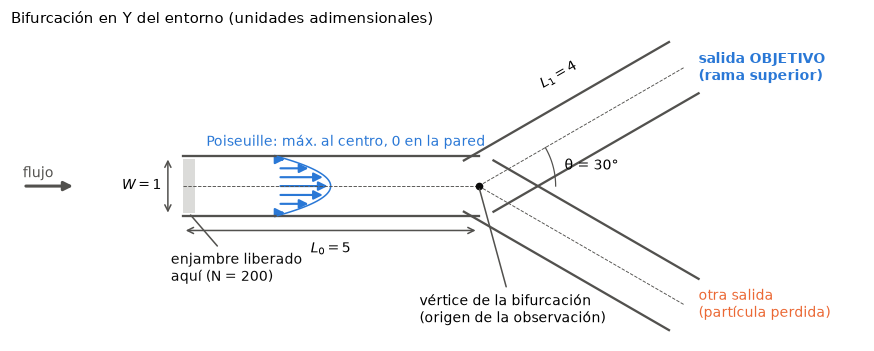

### 0.2 Políticas de referencia (heurísticas)

Todavía no hay agente entrenado. El entorno se evalúa con cuatro políticas **fijas**: ninguna aprende ni cambia entre variantes. Todas aplican una **fuerza común** a las 200 partículas, con acción $a_t \in [-1, 1]^2$ y norma ≤ 1 ($F_{\max}$ fija).

| Política | Regla | Para qué sirve |
|---|---|---|
| **Sin fuerza** | $a_t = 0$ | Reparto natural del flujo (≈ 50/50): el piso a superar |
| **Aleatoria** | $a_t \sim \mathcal{U}([-1, 1]^2)$ en cada paso | Control sin estrategia |
| **Heur. perpendicular** | Si el centroide del enjambre está a menos de 2 del vértice, antes de llegar, empuja a fuerza máxima **perpendicular al canal madre**, hacia el lado de la rama objetivo; fuera de esa zona, $a_t = 0$ | Regla de "desviar justo antes de la bifurcación" |
| **Heur. rama** | Empuja siempre a fuerza máxima **en la dirección de la rama objetivo**, $(\cos 30°, \sin 30°)$ | Regla simple; referencia principal |

En la figura, cada panel muestra la dirección de la fuerza (flechas negras) y el enjambre en un mismo instante del episodio, en el entorno final (Var3) con flujo estacionario (R2).

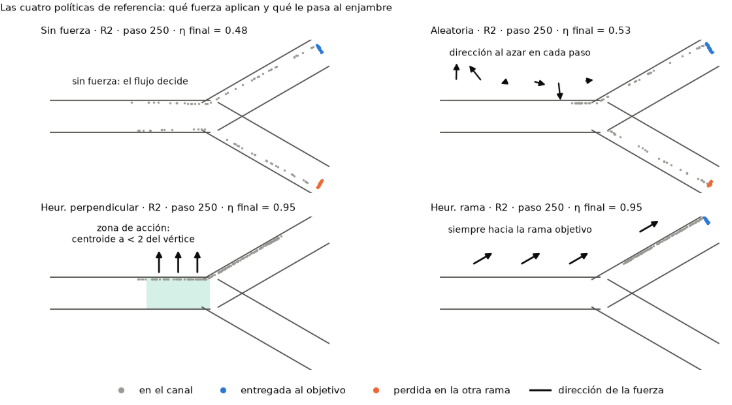

## 1. Experimentos A/B

### 1.1 Diseño

Las variantes son acumulativas: cada una agrega **un solo cambio** a la anterior.
- **Evaluación:** cuatro políticas de referencia (sin fuerza, aleatoria, heurística perpendicular y heurística rama) en R1–R4, 30 episodios por celda, con las mismas semillas de reporte en todas las variantes (comparación pareada).
- **Por qué políticas fijas:** no aprenden, así que las diferencias entre variantes se atribuyen al entorno.

| Variante | Cambio | Defecto | Criterio de éxito (fijado antes de medir) |
|---|---|---|---|
| Baseline | Entorno v0.1 | — | — |
| **Var1** | Pesos de la recompensa | 1 | Spearman retorno–η ≥ 0.9 en R2 y R3; la heur. perpendicular obtiene menos retorno que "sin fuerza" en R2 |
| **Var2** | + radio finito de partícula, $a = 0.05\,W$ | 2 | La heur. perpendicular deja de atascarse en R2 (η > 0.5) |
| **Var3** | + pulso de mayor amplitud y período ($A$: 0.5 → 0.9, $T$: 4 → 20) | 3 | η(R3) ≠ η(R2) en ambas heurísticas (IC 95 % disjuntos) |

**Logs** (uno por experimento): `logs/metrics_sprint2_<variante>.txt`. Cada uno guarda metadatos, configuración, η con IC 95 %, secundarias, alineación retorno–η y tiempo de cómputo.

### 1.2 Baseline (entorno v0.1)

In [4]:
df = {"baseline": run_and_log(VARIANTS["baseline"])}
b = df["baseline"]
display(eta_table(b))
r2 = b[b.condition == "R2"].groupby("policy")[["eta", "return"]].mean()
t = eta_table(b)
print(f"Defecto 1 · Spearman retorno–η: R2 = {reward_alignment(b)['R2']:.2f}, R3 = {reward_alignment(b)['R3']:.2f}; "
      f"heur. perpendicular en R2: η = {r2.loc['heur_perp', 'eta']:.2f} con retorno {r2.loc['heur_perp', 'return']:.2f} "
      f"(sin fuerza: η = {r2.loc['zero', 'eta']:.2f}, retorno {r2.loc['zero', 'return']:.2f})")
print(f"Defecto 2 · heur. perpendicular: η = {t.loc['Heur. perpendicular', 'R2']:.2f} en R2 frente a {t.loc['Heur. perpendicular', 'R4']:.2f} en R4")
print(f"Defecto 3 · máx |η(R3) − η(R2)| entre políticas: {(t['R3'] - t['R2']).abs().max():.3f}")

condition,R1,R2,R3,R4
policy,,,,
Sin fuerza,0.000,0.469,4.693e-01,0.462
Aleatoria,0.000,0.450,4.558e-01,0.464
Heur. perpendicular,0.000,0.000,1.667e-04,0.879
Heur. rama,0.976,0.952,9.510e-01,0.916


Defecto 1 · Spearman retorno–η: R2 = 0.72, R3 = 0.55; heur. perpendicular en R2: η = 0.00 con retorno 0.53 (sin fuerza: η = 0.47, retorno 0.53)
Defecto 2 · heur. perpendicular: η = 0.00 en R2 frente a 0.88 en R4
Defecto 3 · máx |η(R3) − η(R2)| entre políticas: 0.006


### 1.3 Var1: pesos de la recompensa
De Madany 2025 propuesto:
$$r_t = w_p\,\Delta \bar{d} + w_e\,\Delta \eta_{\text{obj}} - w_m\,\Delta \eta_{\text{otras}} - w_u \lVert a_t \rVert^2$$

Con los pesos de v0.1 ($w_p = w_e = w_m = 1$, $w_u = 5\cdot10^{-4}$) hay tres distorsiones:
- **El *shaping* premia acercarse sin entregar.**
- **$w_m = w_e$ anula el reparto natural:** "no actuar" suma ≈ 0.
- **El costo de esfuerzo supera las diferencias de η** entre buenas estrategias.



Como los pesos no alteran la dinámica, se simula una vez con pesos unitarios y el retorno se repondera *offline*. El ajuste queda en `logs/metrics_sprint2_ajuste_recompensa.txt`.

In [5]:
t0 = time.time()
df_tune = evaluate(VARIANTS["baseline"], "ajuste", reward=UNIT_WEIGHTS)
rows = []
for wp in [1.0, 0.5, 0.1]:
    for wm in [1.0, 0.5, 0.25]:
        ret = reweight(df_tune, RewardWeights(progress=wp, target=1.0, other=wm, effort=1e-4))
        rho = reward_alignment(df_tune, ret)
        m = df_tune.assign(ret=ret).groupby(["condition", "policy"]).ret.mean()
        rows.append({"w_p": wp, "w_m": wm, "ρ R2": rho["R2"], "ρ R3": rho["R3"], "ρ R4": rho["R4"],
                     "perp < sin fuerza (R2)": m["R2", "heur_perp"] < m["R2", "zero"]})
grid = pd.DataFrame(rows)
grid["cumple"] = (grid["ρ R2"] >= 0.9) & (grid["ρ R3"] >= 0.9) & grid["perp < sin fuerza (R2)"]
grid["ρ mín"] = grid[["ρ R2", "ρ R3", "ρ R4"]].min(axis=1)
best = grid[grid.cumple].sort_values("ρ mín", ascending=False).iloc[0]
assert (best.w_p, best.w_m) == (VARIANTS["var1"].reward.progress, VARIANTS["var1"].reward.other)

with open(ROOT / "logs" / "metrics_sprint2_ajuste_recompensa.txt", "w", encoding="utf-8") as f:
    f.write("# Sprint 2: ajuste de los pesos de la recompensa (Var1)\n\n")
    f.write("## Metadatos\n" + json.dumps(run_metadata(), indent=2, ensure_ascii=False) + "\n\n")
    f.write(f"## Configuración\nsemillas de ajuste {ajuste[0]}–{ajuste[-1]}; física v0.1; w_e = 1, w_u = 1e-4 (regla); "
            "rejilla w_p ∈ {1, 0.5, 0.1} × w_m ∈ {1, 0.5, 0.25}\n"
            "criterio: ρ ≥ 0.9 en R2 y R3 y retorno(perp) < retorno(sin fuerza) en R2; selección: máx ρ mínima en R2–R4\n\n")
    f.write("## Resultados\n" + grid.to_string(index=False, float_format=lambda x: f"{x:.3f}") + "\n\n")
    f.write(f"Seleccionado: w_p = {best.w_p}, w_m = {best.w_m}\nTiempo de cómputo: {time.time() - t0:.1f} s\n")
print(f"Seleccionado (ajuste): w_p = {best.w_p}, w_m = {best.w_m} · log: logs/metrics_sprint2_ajuste_recompensa.txt")
grid

Seleccionado (ajuste): w_p = 0.1, w_m = 0.5 · log: logs/metrics_sprint2_ajuste_recompensa.txt


,w_p,w_m,ρ R2,ρ R3,ρ R4,perp < sin fuerza (R2),cumple,ρ mín
0,1.0,1.00,0.589,0.586,0.996,False,False,0.586
1,1.0,0.50,0.960,0.952,0.995,True,True,0.952
2,1.0,0.25,0.979,0.977,0.994,True,True,0.977
3,0.5,1.00,0.733,0.684,0.996,False,False,0.684
4,0.5,0.50,0.980,0.974,0.994,True,True,0.974
5,0.5,0.25,0.985,0.984,0.993,True,True,0.984
6,0.1,1.00,0.796,0.792,0.995,True,False,0.792
7,0.1,0.50,0.987,0.985,0.992,True,True,0.985
8,0.1,0.25,0.986,0.983,0.988,True,True,0.983


In [6]:
df["var1"] = run_and_log(VARIANTS["var1"])
assert np.allclose(df["var1"].eta, df["baseline"].eta)  # solo cambió la recompensa: η idéntica
pd.DataFrame({v: reward_alignment(df[v]) for v in ["baseline", "var1"]}).T.round(3)

,R1,R2,R3,R4
baseline,0.812,0.717,0.545,0.927
var1,0.812,0.975,0.970,0.995


### 1.4 Var2: radio finito de partícula

Con partículas puntuales, una partícula empujada contra la pared queda donde el perfil de Poiseuille vale cero y no avanza más. Con radio $a$, el centro rebota a distancia $a$ de la pared, donde la velocidad del flujo es positiva. El radio se aplica en los cuatro niveles, porque es una propiedad de la partícula y no del nivel de fidelidad.

condition,R1,R2,R3,R4
heur. perpendicular,,,,
var1,0.0,0.00,1.667e-04,0.879
var2,0.0,0.95,9.507e-01,0.899


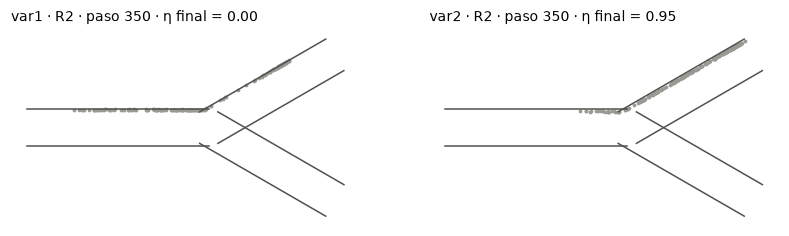

In [7]:
df["var2"] = run_and_log(VARIANTS["var2"])
display(pd.DataFrame({v: df[v][df[v].policy == "heur_perp"].groupby("condition").eta.mean()
                      for v in ["var1", "var2"]}).T.rename_axis("heur. perpendicular"))

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
for ax, v in zip(axes, ["var1", "var2"]):
    env = make_env(VARIANTS[v], "R2")
    s, rec = run_episode(env, make_policy("heur_perp", env), seed=reporte[0], record_every=50)
    pos, status = rec["frames"][6]
    for k in range(3):
        o, tg, n, L = env.geom.origins[k], env.geom.tangents[k], env.geom.normals[k], env.geom.lengths[k]
        for side in (-1, 1):
            a0 = o + side * env.geom.half_width * n
            ax.plot(*np.c_[a0, a0 + L * tg], color="#52514e", lw=1)
    for st, c in {ACTIVE: "#9a9993", AT_TARGET: "#2a78d6", AT_OTHER: "#eb6834"}.items():
        ax.scatter(*pos[status == st].T, s=6, color=c, linewidths=0)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{v} · R2 · paso 350 · η final = {s['eta']:.2f}", loc="left", fontsize=9)
plt.show()

### 1.5 Var3: pulso de mayor amplitud y período

Con la misma geometría y sin fuerza, el flujo pulsátil cuasiestacionario solo reescala en el tiempo el campo estacionario: las trayectorias son las mismas y η no cambia. Un pulso más intenso ($A = 0.9$, el flujo casi se detiene) y más lento ($T = 20$, comparable al tiempo de cruce de la bifurcación) altera la razón fuerza/flujo a lo largo del episodio.

In [8]:
df["var3"] = run_and_log(VARIANTS["var3"])
display(eta_table(df["var3"]))
for pol in ["heur_perp", "heur_branch"]:
    print(f"{LABELS[pol]}: ¿η(R3) ≠ η(R2)? {separated(df['var3'], pol)}")

condition,R1,R2,R3,R4
policy,,,,
Sin fuerza,0.00,0.469,0.469,0.472
Aleatoria,0.00,0.461,0.488,0.480
Heur. perpendicular,0.00,0.950,0.950,0.835
Heur. rama,0.98,0.955,0.954,0.871


Heur. perpendicular: ¿η(R3) ≠ η(R2)? False
Heur. rama: ¿η(R3) ≠ η(R2)? False


## 2. Resultados comparables

### 2.1 Tabla estándar

Columnas:
- **η R1–R4:** heurística rama, la referencia principal.
- **η perp. R2:** heurística perpendicular en R2.
- **ρ mín R2–R3:** alineación retorno–η.
- **Secundarias:** fracción perdida, tiempo de tránsito y esfuerzo de control, de la heurística rama, promedio de R1–R4.
- **Costo:** segundos de cómputo de los 480 episodios, en paralelo.

In [9]:
ORDER = list(VARIANTS)
rows = []
for v in ORDER:
    d = df[v]; br = d[d.policy == "heur_branch"]; e = br.groupby("condition").eta.mean(); rho = reward_alignment(d)
    rows.append({"variante": v, "cambio": VARIANTS[v].change, **{f"η {c}": e[c] for c in ["R1", "R2", "R3", "R4"]},
                 "η perp. R2": d[(d.policy == "heur_perp") & (d.condition == "R2")].eta.mean(),
                 "|η R3 − η R2|": abs(e["R3"] - e["R2"]), "ρ mín R2–R3": min(rho["R2"], rho["R3"]),
                 "pérdida": br.eta_other.mean(), "tránsito": br.transit.mean(), "esfuerzo": br.effort.mean(),
                 "costo (s)": d.attrs["elapsed"]})
table = pd.DataFrame(rows).set_index("variante")


def clear_inversions(d, tol=0.02):
    # pares de políticas en que la que entrega claramente menos (> tol de η) obtiene más retorno
    m = d.groupby(["condition", "policy"])[["eta", "return"]].mean()
    return int(sum((m.loc[c].loc[a, "eta"] > m.loc[c].loc[b_, "eta"] + tol) and
                   (m.loc[c].loc[a, "return"] < m.loc[c].loc[b_, "return"])
                   for c in m.index.levels[0] for a in m.loc[c].index for b_ in m.loc[c].index))


crit = pd.DataFrame({v: {
    "1. ρ ≥ 0.9 en R2 y R3": table.loc[v, "ρ mín R2–R3"] >= 0.9,
    "1b. Sin inversiones claras retorno/η (chequeo posterior)": clear_inversions(df[v]) == 0,
    "2. Sin atasco en pared (η perp. R2 > 0.5)": table.loc[v, "η perp. R2"] > 0.5,
    "3. η(R3) ≠ η(R2) en ambas heurísticas": separated(df[v], "heur_perp") and separated(df[v], "heur_branch"),
} for v in ORDER}).replace({True: "✓", False: "✗"})

with open(ROOT / "logs" / "metrics_sprint2_comparacion.txt", "w", encoding="utf-8") as f:
    f.write("# Sprint 2: comparación de variantes (semillas de reporte 9000–9029)\n\n")
    f.write("## Metadatos\n" + json.dumps(run_metadata(), indent=2, ensure_ascii=False) + "\n\n")
    f.write("## Tabla estándar\n" + table.to_string(float_format=lambda x: f"{x:.3f}") + "\n\n")
    f.write("## Criterios\n" + crit.to_string() + "\n")
display(table.style.format(precision=3).format("{:.0f}", subset=["costo (s)"]))
crit

,cambio,η R1,η R2,η R3,η R4,η perp. R2,|η R3 − η R2|,ρ mín R2–R3,pérdida,tránsito,esfuerzo,costo (s)
variante,,,,,,,,,,,,
baseline,Entorno v0.1 (Sprint 1),0.976,0.952,0.951,0.916,0.000,0.001,0.545,0.009,20.166,1.000,94
var1,Recompensa corregida,0.976,0.952,0.951,0.916,0.000,0.001,0.970,0.009,20.166,1.000,96
var2,+ radio de partícula a = 0.05 W,0.980,0.955,0.956,0.918,0.950,0.001,0.860,0.009,16.973,1.000,83
var3,"+ pulso fuerte y lento (A = 0.9, T = 20)",0.980,0.955,0.954,0.871,0.950,0.001,0.860,0.020,15.608,1.000,81


,baseline,var1,var2,var3
1. ρ ≥ 0.9 en R2 y R3,✗,✓,✗,✗
1b. Sin inversiones claras retorno/η (chequeo posterior),✗,✓,✓,✓
2. Sin atasco en pared (η perp. R2 > 0.5),✗,✗,✓,✓
3. η(R3) ≠ η(R2) en ambas heurísticas,✗,✗,✗,✗


**Criterio 1 a partir de Var2.** En R2 ambas heurísticas alcanzan el techo (η ≈ 0.95, con diferencias de milésimas). La recompensa prefiere la que usa menos esfuerzo de control, que es lo esperado, y el orden por η dentro de ese empate es ruido, lo que reduce ρ. El chequeo 1b, **agregado después de ver el resultado**, verifica que ninguna política que entrega claramente menos obtenga más retorno.

### 2.2 Gráfico clave: η por nivel de fidelidad en cada variante

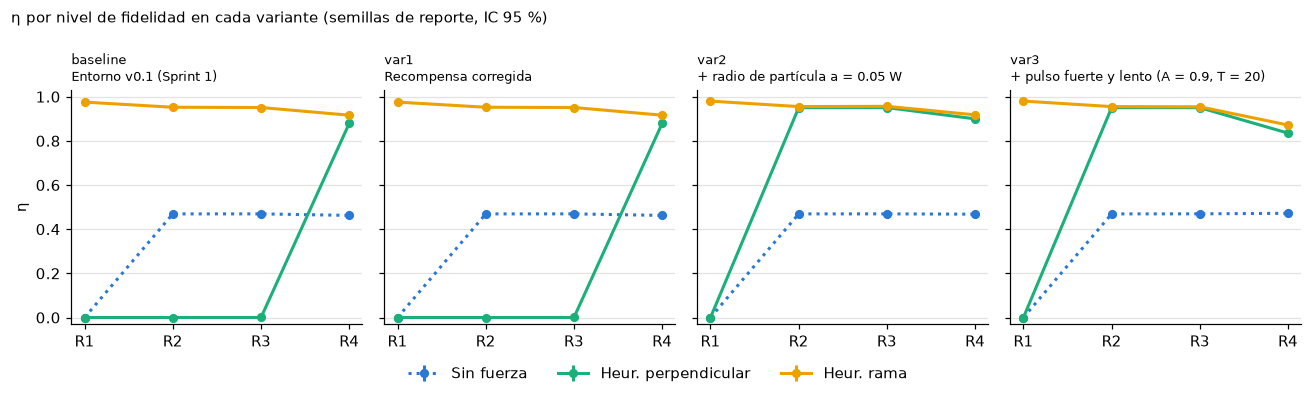

In [10]:
fig, axes = plt.subplots(1, len(ORDER), figsize=(12, 3.3), sharey=True)
for ax, v in zip(axes, ORDER):
    s = summarize(df[v]).set_index(["policy", "condition"])
    for pol in ["zero", "heur_perp", "heur_branch"]:
        y, lo, hi = (np.array([s.loc[(pol, c), k] for c in ["R1", "R2", "R3", "R4"]]) for k in ["eta", "eta_lo", "eta_hi"])
        ax.errorbar(range(4), y, yerr=[y - lo, hi - y], color=COLORS[pol], lw=2, marker="o", ms=5,
                    ls=":" if pol == "zero" else "-", label=LABELS[pol])
    ax.set_xticks(range(4), ["R1", "R2", "R3", "R4"]); ax.set_ylim(-0.03, 1.03); ax.grid(axis="x", visible=False)
    ax.set_title(f"{v}\n{VARIANTS[v].change}", loc="left", fontsize=8.5)
axes[0].set_ylabel("η")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("η por nivel de fidelidad en cada variante (semillas de reporte, IC 95 %)", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "fig5_sprint2_variantes.png", bbox_inches="tight", dpi=130)
plt.show()

## 3. Feature set y pipeline

### 3.1 Features (observación del agente)

| Feature | Tipo de feature engineering |
|---|---|
| Centroide $(x, y)$ relativo a la bifurcación | Creación (estadístico del conjunto) + cambio de origen |
| Dispersión $(x, y)$ | Creación (desviación estándar) |
| Fracciones entregada, perdida y activa | Ratios (conteo / $N$) |
| Fase del pulso $(\sin\varphi, \cos\varphi)$ | Codificación cíclica |
| Acción previa $a_{t-1}$ | Lag |

**Agregadas o quitadas en este sprint:** ninguna; la ablación actúa sobre el entorno, no sobre la observación.

### 3.2 Transformación: estandarización ajustada solo con entrenamiento

Las features tienen escalas distintas (el centroide llega a ±5; las fracciones van de 0 a 1), así que se estandarizan con $(x - \mu)/\sigma$. $\mu$ y $\sigma$ se ajustan con las semillas de **ajuste** y se aplican, congeladas, a las de **reporte**. En PPO se hará con `VecNormalize`: estadísticas congeladas al evaluar (`training=False`) y propias de cada $\pi_{R_i}$ en la matriz cruzada.

In [11]:
def collect_obs(seeds, variant="var3"):
    obs = []
    for cond in ["R1", "R2", "R3", "R4"]:
        env = make_env(VARIANTS[variant], cond)
        for pol in ["random", "heur_branch"]:
            for s in seeds[:5]:
                obs.append(run_episode(env, make_policy(pol, env, seed=s + 10_000), s, record_every=10_000)[1]["obs"])
    return np.concatenate(obs)


X_fit, X_eval = collect_obs(ajuste), collect_obs(reporte)
mu, sigma = X_fit.mean(0), X_fit.std(0) + 1e-8          # fit: solo semillas de ajuste
Z = (X_eval - mu) / sigma                                # transform: semillas de reporte
pd.DataFrame({"min (reporte)": X_eval.min(0), "max (reporte)": X_eval.max(0), "μ (ajuste)": mu, "σ (ajuste)": sigma,
              "media z (reporte)": Z.mean(0), "desv z (reporte)": Z.std(0)}, index=OBS_NAMES).round(2)

,min (reporte),max (reporte),μ (ajuste),σ (ajuste),media z (reporte),desv z (reporte)
centroid_x,-5.00,3.26,-1.01,2.89,0.01,1.01
centroid_y,-2.30,2.39,0.35,0.84,0.06,1.04
spread_x,0.00,2.24,0.50,0.52,-0.04,0.98
spread_y,0.00,2.24,0.43,0.46,-0.07,0.95
frac_target,0.00,0.99,0.15,0.23,-0.02,0.98
frac_other,0.00,0.82,0.08,0.15,0.07,1.12
frac_active,0.01,1.00,0.77,0.33,-0.02,1.02
phase_sin,-1.00,1.00,0.12,0.69,0.02,1.00
phase_cos,-1.00,1.00,-0.01,0.71,-0.01,1.00
prev_action_x,-0.99,1.00,0.38,0.59,-0.02,1.01


### 3.3 Partición y control de fuga

En RL los datos los genera el simulador; lo que se particiona son las **semillas** de los episodios:

| Partición | Semillas | Equivalente en ML | Uso |
|---|---|---|---|
| Ajuste | 5000–5019 | Entrenamiento / validación | Todas las decisiones (pesos de la recompensa) y el *fit* de la normalización |
| Reporte | 9000–9029 | Prueba | Solo resultados finales |

**Verificaciones:**
- Las particiones son disjuntas, también para la política aleatoria (celda siguiente).
- Las decisiones solo usan ajuste (1.3).
- La normalización se ajusta solo con ajuste (3.2).
- No hay fuga entre geometrías: por ahora hay una sola; cuando se agreguen, la de prueba se aislará desde el inicio.

In [12]:
assert not set(ajuste) & set(reporte)
assert not {s + 10_000 for s in ajuste} & {s + 10_000 for s in reporte}  # semillas de la política aleatoria
print(f"Ajuste {ajuste[0]}–{ajuste[-1]} · Reporte {reporte[0]}–{reporte[-1]} · particiones disjuntas ✓")

Ajuste 5000–5019 · Reporte 9000–9029 · particiones disjuntas ✓


## 4. Validación (holdout)

Las decisiones se tomaron con las semillas de ajuste. Si no dependen de esas semillas en particular, los resultados del entorno final (Var3) deben repetirse con las semillas de reporte, que no participaron en ninguna decisión.

In [13]:
df_a = evaluate(VARIANTS["var3"], "ajuste")
hold = pd.DataFrame({"ajuste": df_a.groupby(["policy", "condition"]).eta.mean(),
                     "reporte": df["var3"].groupby(["policy", "condition"]).eta.mean()})
hold["Δ"] = hold["reporte"] - hold["ajuste"]
print(f"máx |Δη| entre particiones: {hold['Δ'].abs().max():.3f}")
print("ρ ajuste :", {k: round(v, 3) for k, v in reward_alignment(df_a).items()})
print("ρ reporte:", {k: round(v, 3) for k, v in reward_alignment(df["var3"]).items()})
hold.unstack("condition")

máx |Δη| entre particiones: 0.036
ρ ajuste : {'R1': np.float64(0.813), 'R2': np.float64(0.858), 'R3': np.float64(0.88), 'R4': np.float64(0.997)}
ρ reporte: {'R1': np.float64(0.812), 'R2': np.float64(0.86), 'R3': np.float64(0.865), 'R4': np.float64(0.997)}


ajuste                      reporte                           Δ  \
condition       R1     R2     R3     R4      R1     R2     R3     R4     R1   
policy                                                                        
heur_branch  0.979  0.957  0.955  0.872    0.98  0.955  0.954  0.871  0.001   
heur_perp    0.000  0.950  0.950  0.835    0.00  0.950  0.950  0.835  0.000   
random       0.000  0.497  0.502  0.494    0.00  0.461  0.488  0.480  0.000   
zero         0.000  0.470  0.470  0.481    0.00  0.469  0.469  0.472  0.000   

                                              
condition           R2         R3         R4  
policy                                        
heur_branch -1.833e-03 -3.333e-04 -7.500e-04  
heur_perp    8.333e-05  8.333e-05  2.500e-04  
random      -3.608e-02 -1.367e-02 -1.392e-02  
zero        -8.333e-04 -5.551e-17 -9.417e-03

**Lectura del holdout.**

- **Heurísticas:** η coincide entre ajuste y reporte con diferencias menores a 0.002 en todos los niveles.
- **Política aleatoria:** la diferencia máxima (0.036) viene de ella, cuya variabilidad entre episodios es intrínseca, no un efecto de las decisiones.
- **Alineación retorno–η:** se reproduce en ambas particiones (R2: 0.86 frente a 0.86; R4: 0.997 frente a 0.997).

**Conclusión:** las decisiones del sprint (pesos de la recompensa, elegidos solo con semillas de ajuste) no están sobreajustadas a esas semillas, y los resultados reportados en la sección 2 generalizan a episodios no vistos.

## 5. Conclusiones y siguiente sprint

### 5.1 Resultado de cada variante (semillas de reporte)

| Variante | Resultado | Criterio | ¿Se adopta? |
|---|---|:---:|:---:|
| **Var1** recompensa | Spearman retorno–η: R2 0.72 → **0.98**, R3 0.55 → **0.97**. La heur. perpendicular en R2 pasa a obtener menos retorno que "sin fuerza" | ✓ | Sí |
| **Var2** radio finito | Heur. perpendicular en R2: η 0.00 → **0.95**; desaparece el atasco en la pared | ✓ | Sí |
| **Var3** pulso A = 0.9, T = 20 | η(R3) = η(R2) en ambas heurísticas (rama: 0.954 frente a 0.955); R4 baja de 0.918 a 0.871 | ✗ | Sí, como diseño de R3; su efecto se verifica con PPO |

**Entorno resultante:** Var3 (física v0.1 + radio $a = 0.05\,W$ + pulso $A = 0.9$, $T = 20$; recompensa $w_p = 0.1$, $w_e = 1$, $w_m = 0.5$, $w_u = 10^{-4}$; $F_{\max} = 0.3$ fija).

### 5.2 Qué aportó más y por qué

- **Var1 y Var2 son las que más aportan:** eliminan los dos defectos que sesgarían el entrenamiento. Con la recompensa original, PPO podría maximizar el retorno sin entregar partículas. Con partículas puntuales, aprendería a explotar un artefacto del simulador (el atasco en la pared), que además existe en R2–R3 y no en R4: una diferencia espuria entre niveles que contaminaría la matriz $\pi_{R_i}(R_j)$.
- **Var3 es un resultado negativo informativo.** Con $F_{\max} = 0.3$, las heurísticas resuelven R2 y R3 hasta el techo de η y no usan la fase del pulso, así que con políticas fijas no se puede distinguir R3 de R2. Que R3 sea un problema distinto para una política que **observa la fase** solo se puede comprobar con un agente que aprende.

### 5.3 Validación

- **Heurísticas:** η difiere menos de 0.002 entre las semillas de ajuste y las de reporte.
- **Política aleatoria:** la diferencia máxima es 0.036, ruido propio de la política.
- **Alineación retorno–η:** coincide entre particiones (R2: 0.86 frente a 0.86).
- **Conclusión:** las decisiones no dependen de las semillas con que se tomaron.

### 5.4 Limitaciones

- **Criterio 1 desde Var2:** ρ = 0.86 en R2–R3, por el empate de ambas heurísticas en el techo de η, donde la recompensa prefiere la de menor esfuerzo. El chequeo 1b (posterior) no encuentra inversiones claras retorno/η.
- **Techo de η en 0.95**, porque el episodio termina cuando sale el 95 % del enjambre.
- **Fase inicial del pulso fija** en todos los episodios.
- **$w_p = 0.1$ da una señal densa débil**, lo que puede hacer lento el aprendizaje.
- **Las secundarias de la heur. rama (esfuerzo = 1, tránsito) casi no discriminan**, porque esa regla aplica siempre la fuerza máxima. Serán informativas con PPO.

### 5.5 Siguiente sprint: piloto con PPO

- **Experimento (un cambio):** introducir PPO en el entorno de Var3. Piloto con $\pi_{R_1}, \ldots, \pi_{R_4}$, 3 semillas de entrenamiento y presupuesto reducido; después, un currículo simple R1 → R4.
- **Tasa de aprendizaje:** se elige $\alpha \in \{10^{-4}, 3\cdot10^{-4}, 10^{-3}\}$ en validación y se usa un único valor, constante, para todos los regímenes.
- **Qué debe verificar el piloto:**
  - que PPO aprende (supera a "sin fuerza" y se acerca a la heur. rama);
  - que η(R3) ≠ η(R2) para PPO;
  - que el retorno se correlaciona con η;
  - que el currículo avanza;
  - que el costo de cómputo es viable.
- **Riesgos y cambios candidatos** (cada uno como un A/B propio):
  - Fin del episodio al 100 % del enjambre, para quitar el techo de η.
  - Fase inicial del pulso aleatoria.
  - Feature derivada "razón fuerza/flujo" ($F_{\max}/U(t)$).
  - `VecNormalize` con estadísticas propias de cada nivel de entrenamiento.

In [14]:
print(f"Tiempo total: {(time.time() - T_START) / 60:.1f} min")

Tiempo total: 10.5 min
